# What pushes a Batman story up BatChat's list?

[Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) found that creator names and dates predict a little of the podcast's taste. This notebook asks the question a fan actually cares about: **which names, which years, which characters?** And do Goodreads readers and critics respond to the same things?

[BatChat](https://comicsxf.com/batchat-rankings/) is a podcast where Matt Lazorwitz and Will Nevin have read and ranked 740 Batman stories. **#1 is best.** We fit one simple model per audience and read off what it learned.

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · snapshot of 21 October 2026*

In [1]:
import warnings
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import DisjointSet
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", module="tqdm")  # shap imports tqdm, which warns about widgets
import shap  # noqa: E402

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv")
issues = pd.read_csv(DATA / "issues.csv")
N = len(stories)
# Higher = more liked, so weights read the same way for BatChat and for star ratings.
stories["batchat_score"] = N - stories["rank"]

## The short version

Numbers are rank places on the 740-story list: +50 means "about 50 places higher, all else equal."

| Pushes a story **up** BatChat's list | Pushes it **down** |
|---|---|
| Grant Morrison (≈ +70), Ed Brubaker, Greg Rucka | Editor Eddie Berganza (≈ −55) |
| The **Joker** as the villain (≈ +50) | **Superman** in the cast (≈ −40) |
| **Bruce Wayne** in the lead (≈ +60); Batgirl- and Robin-led books rank lower | Long arcs |
| Jim Gordon, the GCPD, Gotham's mobs | The Riddler |
| The 1990s Bat-office editors | 2010s–20s production teams |
| A cover date from the **1980s–2000s** | |

Three things hold across the noise. **When a story came out matters more than anything else**, and most creator names are shorthand for which DC they came from. **Only Grant Morrison helps every audience** (Goodreads, critics, and the podcast). And **the Joker splits the room**: BatChat and Goodreads readers reward him, critics punish him. The rest of the notebook shows where each of these comes from and how much to trust it.

## The model, in one paragraph

A linear model gives every feature a weight, and a story's predicted score is the sum of its weights. Each creator and character is a yes/no feature (did this person work on it? is this character in it?); cover year, issue count, and format (comic, graphic novel, prose) complete the list. A name needs **five stories** to get a weight, so one-off credits can't swing the result. The weights *are* the answer to "what drives the ranking"; the rest of this notebook is about reading them carefully.

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = {"narrative_" + r: r[:-1] for r in ROLES}  # column -> label, e.g. "writer"
CAST = {"featured_entity_ids": "featured", "antagonists_entity_ids": "antagonist"}
WHEN = ["cover_year_start", "issue_count"]

X = stories[["medium", "format_hint", *WHEN, *NAMES, *CAST]].copy()
X[[*NAMES, *CAST]] = X[[*NAMES, *CAST]].fillna("")


def model(min_df=5):
    """Ridge regression on scaled numbers, one-hot format, and 0/1 name columns."""
    return make_pipeline(
        ColumnTransformer(
            [
                ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), WHEN),
                (
                    "format",
                    OneHotEncoder(handle_unknown="ignore", min_frequency=3),
                    ["medium", "format_hint"],
                ),
                *[
                    (
                        label,
                        CountVectorizer(
                            token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=min_df
                        ),
                        col,
                    )
                    for col, label in {**NAMES, **CAST}.items()
                ],
            ]
        ),
        RidgeCV(alphas=np.logspace(-1, 3, 9)),
    )


def pretty(feature):
    """'writer__Frank Miller' -> 'Frank Miller (writer)'; characters lose their universe tag."""
    kind, _, value = feature.partition("__")
    if kind in {"num", "format"}:
        return (
            value.replace("format_hint_", "format: ")
            .replace("cover_year_start", "cover year")
            .replace("issue_count", "issue count")
        )
    return f"{value.split(' (')[0]} ({kind})"


def weights_of(fitted):
    """Weight per pretty feature name. Characters that appear under two universe tags are merged."""
    w = pd.Series(fitted[-1].coef_, index=fitted[0].get_feature_names_out()).rename(pretty)
    return w.groupby(level=0).sum()


def weight_bars(ax, weights, n, faded=()):
    """Horizontal bars of the n strongest positive and negative weights; `faded` names drawn grey."""
    top = pd.concat([weights.nlargest(n), weights.nsmallest(n)]).sort_values()
    colors = [GREY if name in faded else (BLUE if v > 0 else ORANGE) for name, v in top.items()]
    ax.barh(top.index, top, color=colors)
    ax.axvline(0, color=GREY, lw=1)

## 1. BatChat: who and what moves a story up the list?

Each weight is in rank places: +60 means that, all else equal, this name is worth about 60 places higher. Blue helps, orange hurts. **Grey bars are names that did not pass the stability check in section 2.**

Two cautions. A weight is *what's left after everything else in the model has been credited*: a writer's weight sits on top of whatever the model already gave his artists and his years. And a weight is a pattern inside the hosts' list, not a verdict on anyone's career.

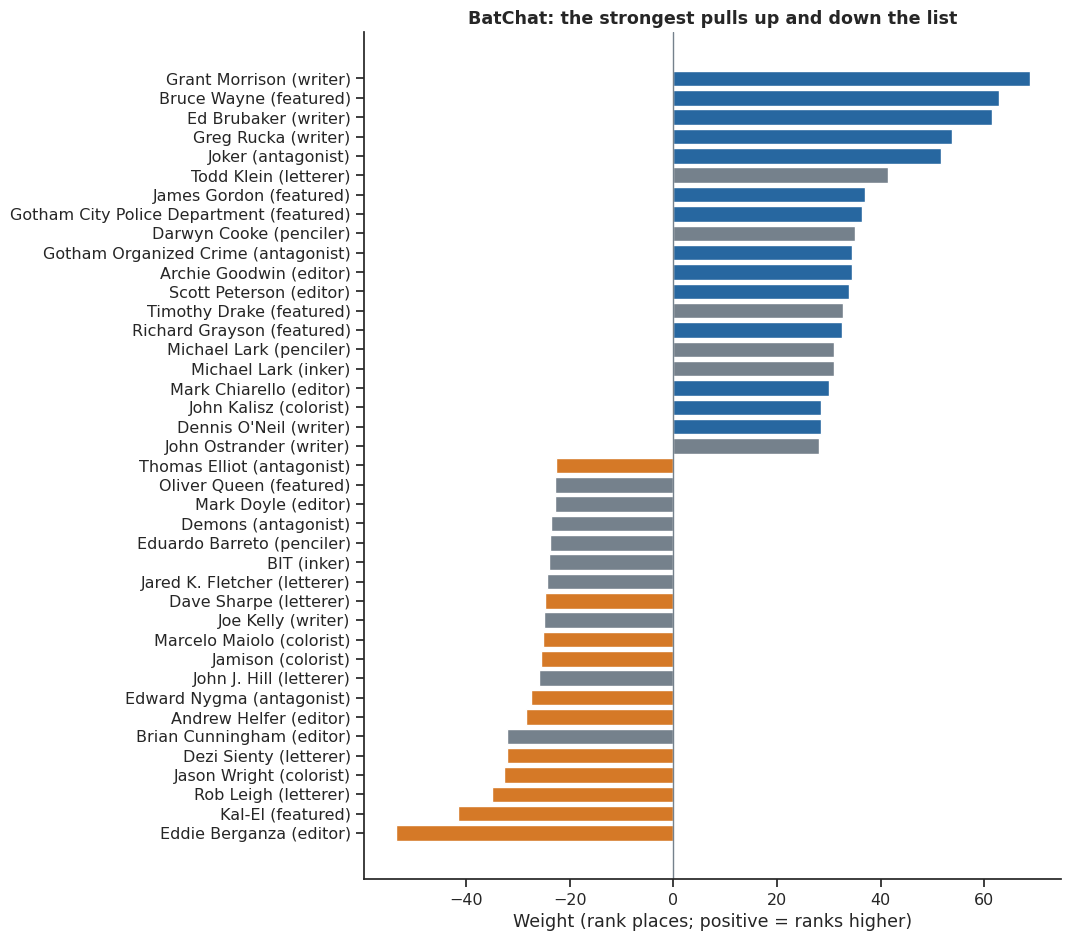

On stories it never saw, the model misses by about 173 places. 55 names passed the stability check.


In [3]:
# Stories that share an issue or a podcast episode stay in the same fold, so a model is never
# tested on the other half of an arc it trained on.
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
linked = DisjointSet(stories.story_id)
for _, ids in links.groupby("key").story_id:
    for a, b in pairwise(ids):
        linked.merge(a, b)
label = {story: min(group) for group in linked.subsets() for story in group}
groups = stories.story_id.map(label).to_numpy()
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

y = stories.batchat_score
batchat_model = model().fit(X, y)
batchat_weights = weights_of(batchat_model)

# One fit per fold does triple duty: held-out predictions, the shuffle test, and the stability test.
blocks = {
    "Year + length": WHEN,
    "Format": ["medium", "format_hint"],
    "Writers": ["narrative_writers"],
    "Pencilers + inkers": ["narrative_pencilers", "narrative_inkers"],
    "Colors + letters + editors": [
        "narrative_colorists",
        "narrative_letterers",
        "narrative_editors",
    ],
    "Characters": list(CAST),
}
held_out = np.empty(N)
shuffle_cost, fold_weights = [], []
rng = np.random.default_rng(0)
for k, (train, test) in enumerate(folds):
    fitted = model().fit(X.iloc[train], y.iloc[train])
    held_out[test] = fitted.predict(X.iloc[test])
    fold_weights.append(weights_of(fitted).rename(k))
    base = mean_absolute_error(y.iloc[test], held_out[test])
    for block, cols in blocks.items():
        shuffled = X.iloc[test].copy()
        shuffled[cols] = shuffled[cols].sample(frac=1, random_state=rng.integers(1e6)).to_numpy()
        shuffle_cost.append(
            {
                "block": block,
                "worse by": mean_absolute_error(y.iloc[test], fitted.predict(shuffled)) - base,
            }
        )
shuffle_cost = pd.DataFrame(shuffle_cost)
fold_weights = pd.concat(fold_weights, axis=1).fillna(0)
stable = fold_weights.index[
    (np.sign(fold_weights).nunique(axis=1) == 1) & (fold_weights.abs().min(axis=1) > 10)
]
unstable = set(batchat_weights.index) - set(stable)

fig, ax = plt.subplots(figsize=(9, 11))
weight_bars(ax, batchat_weights, 20, faded=unstable)
ax.set(
    xlabel="Weight (rank places; positive = ranks higher)",
    title="BatChat: the strongest pulls up and down the list",
)
plt.show()
print(
    f"On stories it never saw, the model misses by about {mean_absolute_error(y, held_out):.0f} places. "
    f"{len(stable)} names passed the stability check."
)

**Grant Morrison is the strongest pull, about +70 places.** Then Ed Brubaker and Greg Rucka, the writers of *Gotham Central*; the GCPD, Jim Gordon, and Gotham's mobs as cast; and the editors Archie Goodwin, Scott Peterson, and Mark Chiarello. The hosts like crime stories, and they like the people who edited the 1990s Bat-office.

Two character weights stand out. **A story with the Joker as antagonist gains about 50 places**, and **a story where Bruce Wayne is a featured character gains about 60**: the Batgirl, Robin, and Nightwing-led books, where he isn't, rank worse. **Superman as a featured character costs about 40.** The hosts prefer Batman alone, in Gotham, against the Joker.

The biggest drag is editor **Eddie Berganza**, about −55, followed by a run of 2010s–2020s letterers and colorists (Rob Leigh, Jason Wright, Dezi Sienty). Those names are shorthand for an era of DC the hosts don't rate.

### Why isn't Tom King on that chart?

He wrote **#3** (*Cold Days*) and **#7** (*Some of These Days*). He also wrote **#703** (*The Wedding*) and **#738** (*Dreadful Reins*). Across his 24 stories the typical (median) rank is 415 and the middle half spans 115 to 584, the widest spread of any prolific writer. A name only earns a weight when its books cluster, and his don't. Below, the twelve most-credited writers, each box the middle half of their stories; the model's weight is at the end of each label.

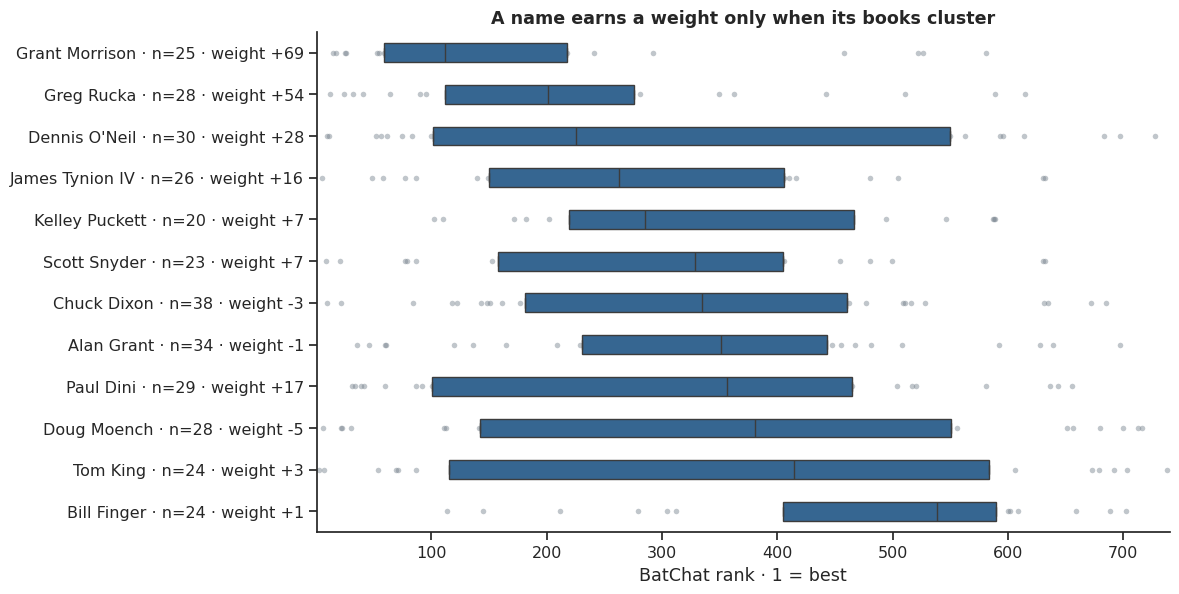

In [4]:
writers = stories.assign(writer=stories.narrative_writers.str.split("|")).explode("writer")
top = writers.writer.value_counts().head(12).index
chart = writers[writers.writer.isin(top)]
order = chart.groupby("writer")["rank"].median().sort_values().index
labels = {
    w: f"{w} · n={chart.writer.eq(w).sum()} · weight {batchat_weights.get(f'{w} (writer)', 0):+.0f}"
    for w in order
}
chart = chart.assign(label=chart.writer.map(labels))
fig, ax = plt.subplots(figsize=(11, 6.5))
common = dict(data=chart, x="rank", y="label", order=[labels[w] for w in order], ax=ax)
sns.stripplot(**common, color=GREY, alpha=0.45, size=4, jitter=False, zorder=0)
sns.boxplot(**common, color=BLUE, whis=0, showfliers=False, width=0.45)
ax.set(
    xlabel="BatChat rank · 1 = best",
    ylabel="",
    xlim=(1, N),
    title="A name earns a weight only when its books cluster",
)
plt.show()

Grant Morrison's 25 stories sit mostly in the top third, so his name is worth about +70. Chuck Dixon's 38 spread across the whole list, so his is worth nothing. Bill Finger's books cluster too, in the bottom third, yet his weight is +1: a name has to explain something the cover year doesn't, and "1940s" already took the blame. A weight is a statement about consistency *beyond the era*; it says nothing about talent.

## 2. Are the big weights real, or noise?

A name on five stories can get a large weight by luck. Two checks:

- **Shuffle test.** Scramble one kind of information at a time (all the writer names, say) across the stories the model was not trained on, and see how much worse its predictions get. A big loss means the model leans on that information.
- **Stability.** Drop a different fifth of the list five times and refit each time. A name keeps its weight only if the sign never flips and the size stays above 10 places every time. Those are the solid bars above; the grey ones failed.

The chart below is the shuffle test; the stability result is already drawn into the first chart.

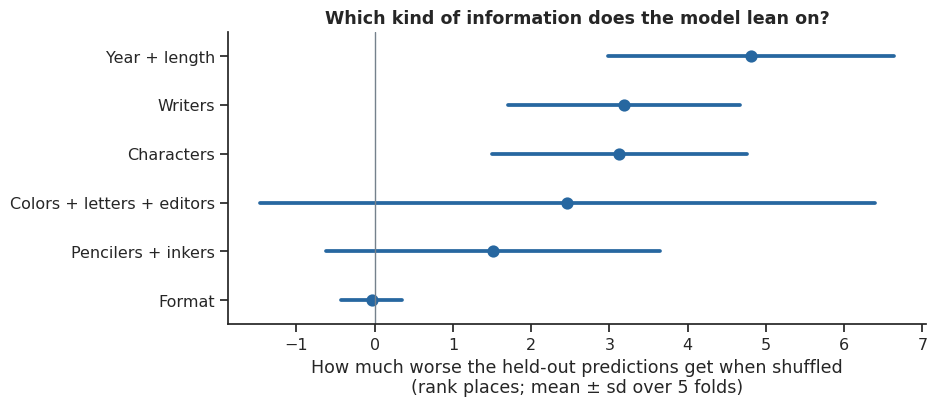

In [5]:
order = shuffle_cost.groupby("block")["worse by"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.pointplot(
    data=shuffle_cost,
    x="worse by",
    y="block",
    order=order,
    errorbar="sd",
    linestyle="none",
    color=BLUE,
    ax=ax,
)
ax.axvline(0, color=GREY, lw=1)
ax.set(
    xlabel="How much worse the held-out predictions get when shuffled\n(rank places; mean ± sd over 5 folds)",
    ylabel="",
    title="Which kind of information does the model lean on?",
)
plt.show()

**Year and length matter most.** Shuffling them costs about five places out of a typical 173-place miss; shuffling writer names or characters about three. Pencilers and inkers barely register, which is surprising for comics until you remember that an artist mostly tells the model which era it's in, and the year already said so. The format column (comic, graphic novel, prose) adds nothing.

The stability check keeps most of the big names. Morrison, Brubaker, Rucka, the Joker, Bruce Wayne, Berganza, and Superman all survive five refits. Darwyn Cooke, Todd Klein, and Michael Lark do not: their weight is real in the full fit but swings with which fifth of the list is left out, so treat them as suggestive.

## 3. Do readers and critics care about the same things?

Same model, now predicting Goodreads stars for the 40 stories we could find there, and reader and critic scores on Comic Book RoundUp, a review-aggregator site, for 110 and 78 stories. With so few books, a name needs only three stories to get a weight here, and individual names are weak evidence. The broad strokes:

| Audience | Pushes a story **up** | Pushes it **down** |
|---|---|---|
| **Goodreads readers** (40) | The Joker, Two-Face · long collections · Todd Klein, Matt Hollingsworth | Matt Wagner · Archie Goodwin, Dennis O'Neil · Bruce Wayne in the lead |
| **RoundUp readers** (110) | Modern editors Maggie Howell, Mark Doyle, Mike Marts · Grant Morrison · the Falcone crime family | Tim Seeley · Tim Drake in the lead · 1990s production (John Costanza, Adrienne Roy) |
| **RoundUp critics** (78) | **Newer** books · Howell, Doyle · colorists John Kalisz, Adriano Lucas | The **Joker** (their biggest negative) · Scarecrow · Tweedledum and Tweedledee |

Below, one panel per audience, BatChat first for comparison: the six strongest pulls each way, in that audience's own units (rank places, stars, or points out of ten).

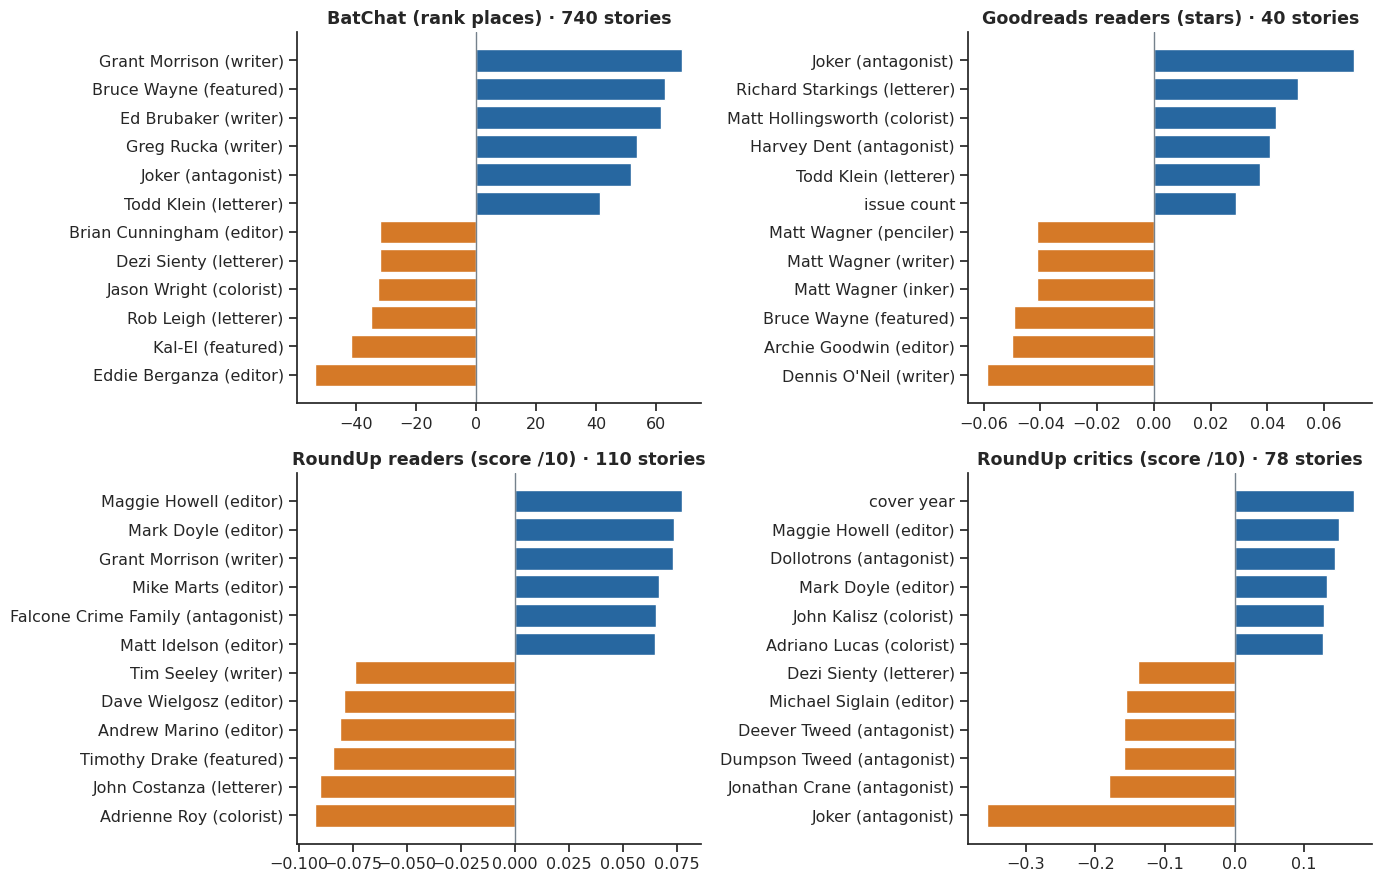

In [6]:
goodreads_ok = stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(
    100
)
roundup_ok = stories.roundup_narrative_scope.eq("all_indexed_narratives")
audiences = {
    "Goodreads readers (stars)": ("goodreads_rating", goodreads_ok),
    "RoundUp readers (score /10)": (
        "roundup_user_rating",
        roundup_ok & stories.roundup_user_complete & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics (score /10)": (
        "roundup_critic_rating",
        roundup_ok & stories.roundup_critic_complete & stories.roundup_critic_min_count.ge(3),
    ),
}
audience_weights = {"BatChat (rank places)": batchat_weights}
for label, (target, ok) in audiences.items():
    audience_weights[label] = weights_of(model(min_df=3).fit(X[ok], stories.loc[ok, target]))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (label, w) in zip(axes.flat, audience_weights.items()):
    weight_bars(ax, w, 6)
    n = N if label.startswith("BatChat") else audiences[label][1].sum()
    ax.set_title(f"{label} · {n} stories")
fig.tight_layout()
plt.show()

The audiences do not react to the same names. **Grant Morrison** is the only name that helps both BatChat and RoundUp readers. **The Joker is BatChat's and Goodreads' favorite villain and the critics' least favorite.** Goodreads rewards long collections and Todd Klein's lettering; BatChat penalizes long arcs. Matt Wagner is a modest plus for BatChat and the single biggest minus on Goodreads. RoundUp readers and critics agree on two editors, Maggie Howell and Mark Doyle, who edited the modern books the hosts rank low.

One pattern is solid across all this noise: BatChat's taste is built on creators from the 1980s–2000s, while Goodreads and the critics lean on characters and recency.

## 4. The mismatches, one story at a time

Since a guess is just weights added up, we can list which names and numbers pushed each story where. (The tool that does this split for any model, not just a linear one, is called [SHAP](https://shap.readthedocs.io/); the methods note explains.) Each panel shows the names and numbers that most pushed the model's guess for that story, **counting only features the story actually has.** Left column: the three stories the hosts liked far more than the model expected. Right column: far less.

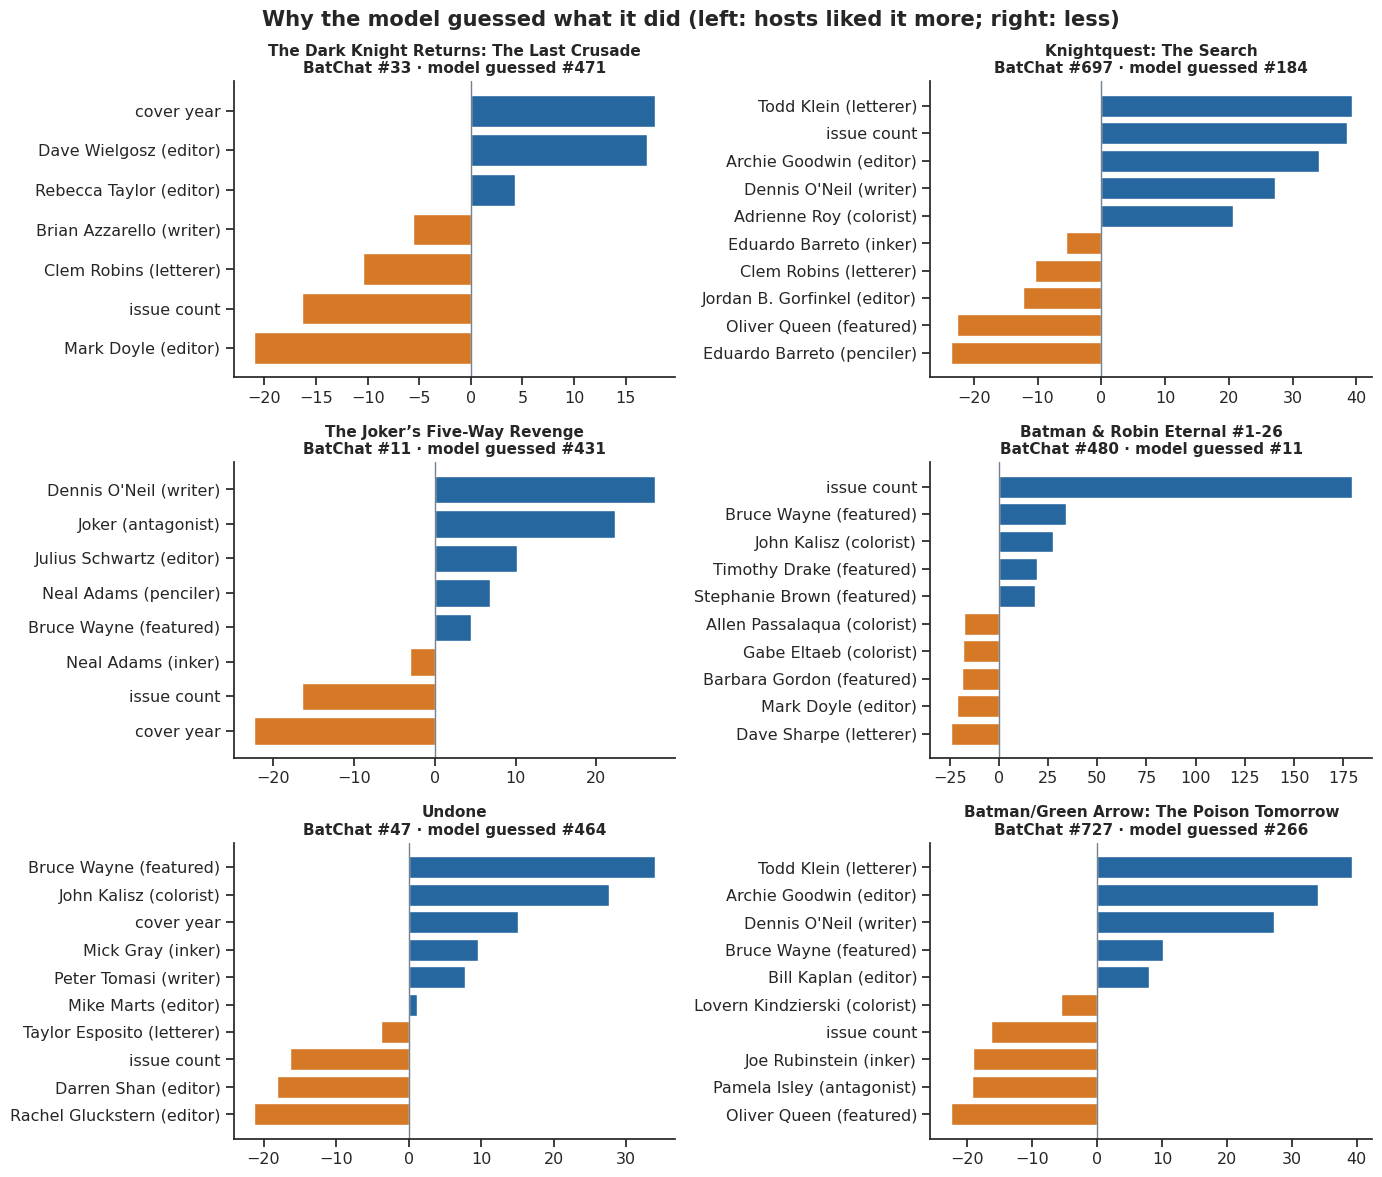

In [7]:
features = batchat_model[0].transform(X)
features = features.toarray() if hasattr(features, "toarray") else features
explainer = shap.LinearExplainer(batchat_model[-1], features)
contrib = pd.DataFrame(
    explainer.shap_values(features),
    columns=batchat_model[0].get_feature_names_out(),
    index=stories.title,
)
present = pd.DataFrame(features != 0, columns=contrib.columns, index=contrib.index)
contrib = contrib.where(present, 0).rename(columns=pretty).T.groupby(level=0).sum().T

surprise = pd.Series(y.to_numpy() - held_out, index=stories.title)
picks = [*surprise.nlargest(3).index, *surprise.nsmallest(3).index]
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, title in zip(axes.T.flat, picks):
    parts = contrib.loc[title]
    weight_bars(ax, parts[parts.abs() > 1], 5)
    rank = int(stories.loc[stories.title.eq(title), "rank"].iloc[0])
    guess = int(N - held_out[stories.title.eq(title)][0])
    ax.set_title(f"{title}\nBatChat #{rank} · model guessed #{guess}", fontsize=11)
fig.suptitle(
    "Why the model guessed what it did (left: hosts liked it more; right: less)", fontweight="bold"
)
fig.tight_layout()
plt.show()

**The hosts' upside surprises are the model being blind to craft.** *The Joker's Five-Way Revenge* (#11) gets credit for Dennis O'Neil, the Joker, and Neal Adams, then loses it all for being one issue from 1973. *Undone* (#47) is lifted by Bruce Wayne and its 2015 cover date and dragged by its editors and its length; nothing in the credits says it's a silent issue about grief.

**The downside surprises are era signals firing on books the hosts hated.** *Knightquest: The Search* (#697) and *The Poison Tomorrow* (#727) get +40 from Todd Klein, +34 from Archie Goodwin, and +27 from Dennis O'Neil: the 1990s Bat-office the hosts usually love. And *Batman & Robin Eternal* (#480) is the model's single worst guess, **#11**, because the model adds the same bonus per issue, so 26 issues collect 26 times the bonus: issue count alone adds 178 places.

## What we can and can't say

- **Yes, there are clear signals.** Grant Morrison, Ed Brubaker, Greg Rucka, the Joker, Jim Gordon and the GCPD, and the 1990s Bat-office editors push a story up BatChat's list. Eddie Berganza, Superman, and a cluster of 2010s colorists and letterers pull it down.
- **The signals are era-shaped.** The single most useful fact is the cover year; most creator weights are shorthand for "which DC was this".
- **They are not the hosts' taste in full.** The model still misses by about 170 places, and its biggest misses are books where craft, not credits, decided it.
- **Outside audiences run on different signals.** Only Grant Morrison helps everyone. The Joker helps BatChat and Goodreads and hurts with critics.

<details><summary>Methods notes</summary>

- **Model:** ridge regression (the penalty chosen by cross-validation from 0.1 to 1000), the same set-up as [the prediction notebook](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories). The one change: a name needs five stories for a weight, not three, to keep one-off credits out of the chart. Targets: BatChat score (740 − rank), Goodreads stars, RoundUp scores.
- **Stability** keeps a name only if its weight has the same sign and is larger than 10 in all five fold refits. A rough filter, not a significance test.
- **Shuffle test** scrambles whole groups of columns at once (`sklearn.inspection.permutation_importance` does the same one column at a time); groups keep correlated names together.
- **SHAP** for a linear model is weight × (value − mean value). We show only features the story has, so an absent name never appears in its breakdown. A tree model with `TreeExplainer` would show interactions, but the prediction notebook found a random forest (a crowd of simple rule-of-thumb models that vote) no more accurate, so the simpler model is the honest one.

</details>

**More BatChat notebooks:** [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [Gotham's rogues, ranked](https://www.kaggle.com/code/danofer/gotham-s-rogues-ranked) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.